# Feature engineering and EDA

## Environment setup and data loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("Set2")

df = pd.read_csv('high_diamond_ranked_10min.csv')

# Preview the first 5 rows to understand the data structure
display(df.head())

,gameId,blueWins,blueWardsPlaced,blueWardsDestroyed,blueFirstBlood,blueKills,blueDeaths,blueAssists,blueEliteMonsters,blueDragons,...,redTowersDestroyed,redTotalGold,redAvgLevel,redTotalExperience,redTotalMinionsKilled,redTotalJungleMinionsKilled,redGoldDiff,redExperienceDiff,redCSPerMin,redGoldPerMin
0,4519157822,0,28,2,1,9,6,11,0,0,...,0,16567,6.8,17047,197,55,-643,8,19.7,1656.7
1,4523371949,0,12,1,0,5,5,5,0,0,...,1,17620,6.8,17438,240,52,2908,1173,24.0,1762.0
2,4521474530,0,15,0,0,7,11,4,1,1,...,0,17285,6.8,17254,203,28,1172,1033,20.3,1728.5
3,4524384067,0,43,1,0,4,5,5,1,0,...,0,16478,7.0,17961,235,47,1321,7,23.5,1647.8
4,4436033771,0,75,4,0,6,6,6,0,0,...,0,17404,7.0,18313,225,67,1004,-230,22.5,1740.4


## Data profiling and basic cleaning

In [2]:
# 1. Check data dimensions (rows, columns)
print(f"Data Shape: {df.shape}")

# 2. Check for missing values
missing_values = df.isnull().sum().sum()
print(f"Total Missing Values: {missing_values}")

# 3. Check for duplicated rows
duplicate_rows = df.duplicated().sum()
print(f"Total Duplicated Rows: {duplicate_rows}")

# 4. Drop meaningless ID column to prevent model overfitting
df = df.drop(columns=['gameId'])
    
# 5. Check data types 
#display(df.info())

Data Shape: (9879, 40)
Total Missing Values: 0
Total Duplicated Rows: 0


## Feature engineering

In [3]:
# 1. Construct intermediate composite metrics for both sides
df['blueKDA'] = (df['blueKills'] + df['blueAssists']) / df['blueDeaths'].replace(0, 1)
df['redKDA'] = (df['redKills'] + df['redAssists']) / df['redDeaths'].replace(0, 1)

df['blueVisionScore'] = df['blueWardsPlaced'] + df['blueWardsDestroyed']
df['redVisionScore'] = df['redWardsPlaced'] + df['redWardsDestroyed']

df['blueObjControl'] = df['blueEliteMonsters'] + df['blueDragons'] + df['blueHeralds']
df['redObjControl'] = df['redEliteMonsters'] + df['redDragons'] + df['redHeralds']

# 2. Transform EVERYTHING into "Gap/Difference" (Blue - Red)
# Positive value means Blue is leading; Negative means Red is leading.
df['blueKDA_Diff'] = df['blueKDA'] - df['redKDA']
df['blueVision_Diff'] = df['blueVisionScore'] - df['redVisionScore']
df['blueObj_Diff'] = df['blueObjControl'] - df['redObjControl']
df['blueTowers_Diff'] = df['blueTowersDestroyed'] - df['redTowersDestroyed']
df['blueMinions_Diff'] = df['blueTotalMinionsKilled'] - df['redTotalMinionsKilled']
df['blueJungle_Diff'] = df['blueTotalJungleMinionsKilled'] - df['redTotalJungleMinionsKilled']
df['blueAvgLevel_Diff'] = df['blueAvgLevel'] - df['redAvgLevel']

# 3. Drop all absolute and redundant features to prevent multicollinearity
cols_to_drop = [
    # Drop granular absolute metrics
    'blueKills', 'blueDeaths', 'blueAssists', 'redKills', 'redDeaths', 'redAssists',
    'blueWardsPlaced', 'blueWardsDestroyed', 'redWardsPlaced', 'redWardsDestroyed',
    'blueEliteMonsters', 'blueDragons', 'blueHeralds', 'redEliteMonsters', 'redDragons', 'redHeralds',
    
    # Drop intermediate absolute composite metrics
    'blueKDA', 'redKDA', 'blueVisionScore', 'redVisionScore', 'blueObjControl', 'redObjControl',
    
    # Drop absolute Gold and Experience (since we already have 'blueGoldDiff' and 'blueExperienceDiff')
    'blueTotalGold', 'redTotalGold', 'blueTotalExperience', 'redTotalExperience',
    
    # Drop other absolute metrics that were converted to Diff
    'blueTowersDestroyed', 'redTowersDestroyed', 
    'blueTotalMinionsKilled', 'redTotalMinionsKilled',
    'blueTotalJungleMinionsKilled', 'redTotalJungleMinionsKilled',
    'blueAvgLevel', 'redAvgLevel',
    
    # Drop mathematically redundant metrics (Per-minute stats are perfectly correlated with 10-min totals)
    'blueCSPerMin', 'redCSPerMin', 'blueGoldPerMin', 'redGoldPerMin',
    
    # Drop Red team's exact opposites (e.g., redFirstBlood is 1 - blueFirstBlood, redGoldDiff is -blueGoldDiff)
    'redFirstBlood', 'redGoldDiff', 'redExperienceDiff'
]

df = df.drop(columns=cols_to_drop)

print(f"Ultimate cleaning completed")
print(f"Current Dataset Shape: {df.shape}")
print(f"Current Clean Features: {df.columns.tolist()}")

Ultimate cleaning completed
Current Dataset Shape: (9879, 11)
Current Clean Features: ['blueWins', 'blueFirstBlood', 'blueGoldDiff', 'blueExperienceDiff', 'blueKDA_Diff', 'blueVision_Diff', 'blueObj_Diff', 'blueTowers_Diff', 'blueMinions_Diff', 'blueJungle_Diff', 'blueAvgLevel_Diff']


## EDA Visualizations

### Heatmap

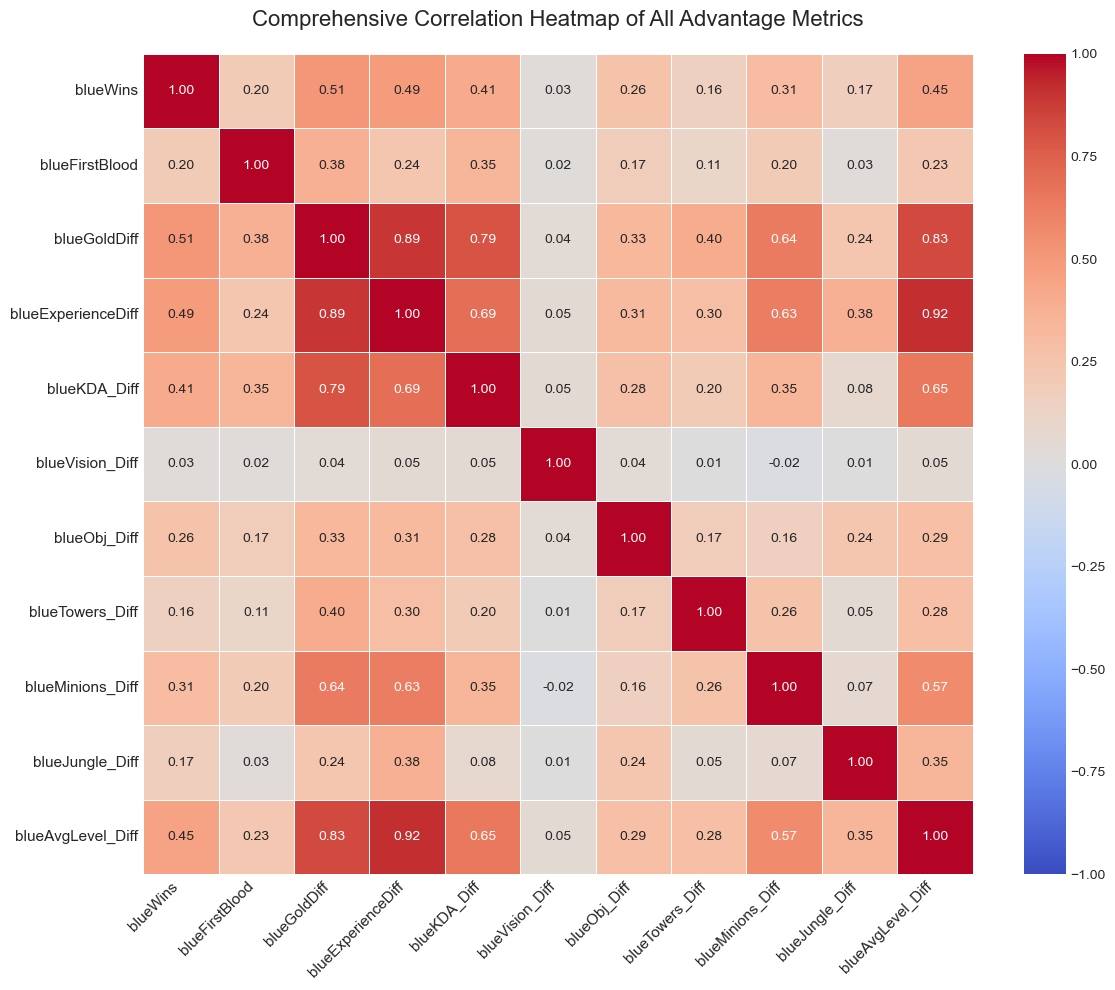

--- Insights: Comprehensive Correlation Heatmap ---
1. Economy Dominates: 'blueGoldDiff' (0.51) is the strongest linear predictor of a win at 10 minutes.
2. The Vision Myth: 'blueVision_Diff' has a surprisingly negligible correlation (0.03) with winning early on, indicating early vision control does not guarantee snowballing.
3. Multicollinearity Alert: A severe correlation of 0.89 exists between Gold Gap and Experience Gap. One must be dropped for linear models to ensure coefficient stability.


In [4]:
plt.figure(figsize=(12, 10))

corr_matrix = df.corr()

sns.heatmap(corr_matrix, 
            annot=True,              # Show numerical values
            cmap='coolwarm',         # Red for positive, Blue for negative
            fmt=".2f",               # Format to 2 decimal places
            vmin=-1, vmax=1,         # Set correlation bounds
            linewidths=0.5,          # Add grid lines for readability
            annot_kws={"size": 10})  # Adjust font size for better fit

plt.title('Comprehensive Correlation Heatmap of All Advantage Metrics', fontsize=16, pad=20)
plt.xticks(rotation=45, ha='right', fontsize=11)
plt.yticks(fontsize=11)
plt.tight_layout()
plt.show()

# Print automated analytical insights
print("--- Insights: Comprehensive Correlation Heatmap ---")
print("1. Economy Dominates: 'blueGoldDiff' (0.51) is the strongest linear predictor of a win at 10 minutes.")
print("2. The Vision Myth: 'blueVision_Diff' has a surprisingly negligible correlation (0.03) with winning early on, indicating early vision control does not guarantee snowballing.")
print("3. Multicollinearity Alert: A severe correlation of 0.89 exists between Gold Gap and Experience Gap. One must be dropped for linear models to ensure coefficient stability.")

### Exploring Distributions, Thresholds, and Non-linear Interactions

--- Insights: Gold Difference Boxplot ---
1. Significant Distribution Shift: The interquartile ranges (IQR) of winning and losing games barely overlap.
2. Clear Benchmark: Maintaining a positive Gold Difference (>0) by the 10-minute mark pushes the game state solidly into the winning distribution.
--- Insights: Epic Objective Gap Barplot ---
1. The Tie-Breaker: A 0 objective gap results in a pure 50/50 coinflip (50.8% win rate).
2. Threshold Effect: Securing just one more epic objective than the enemy (+1) causes the most dramatic win rate spike (+13.4%).
3. Diminishing Returns: As the objective gap increases further (+2, +3), the marginal gain in win rate begins to decrease.
--- Insights: Gold vs. KDA Scatterplot (CORRECTED) ---
1. Inextricable Link: The top-left and bottom-right quadrants are virtually empty. This proves that in High-Diamond games at 10 minutes, Micro (KDA) and Macro (Gold) are strictly bound together; you cannot have a massive gold lead while heavily losing fights.


C:\Users\曹思源\AppData\Local\Temp\ipykernel_29072\2493217052.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=obj_diff_winrate.index, y=obj_diff_winrate.values, ax=axes[1], palette='viridis')


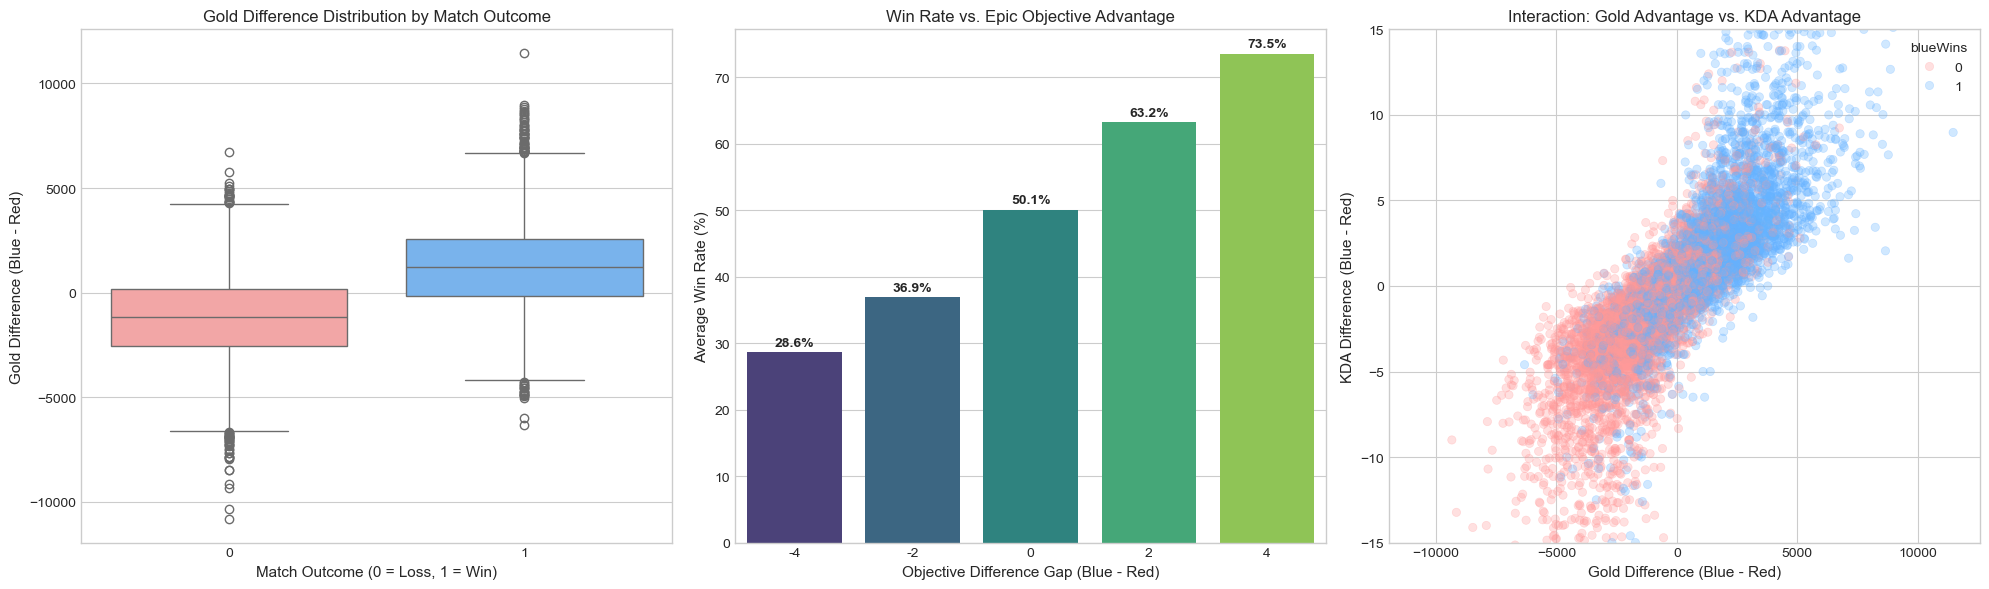

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# Plot 1: Boxplot (Distribution Shift Validation)
# A boxplot clearly shows the median, interquartile range, and outliers for winning vs losing games.
sns.boxplot(x='blueWins', y='blueGoldDiff', data=df, ax=axes[0], palette=['#ff9999', '#66b3ff'],hue='blueWins', legend=False)
axes[0].set_title('Gold Difference Distribution by Match Outcome', fontsize=12)
axes[0].set_xlabel('Match Outcome (0 = Loss, 1 = Win)', fontsize=11)
axes[0].set_ylabel('Gold Difference (Blue - Red)', fontsize=11)
print("--- Insights: Gold Difference Boxplot ---")
print("1. Significant Distribution Shift: The interquartile ranges (IQR) of winning and losing games barely overlap.")
print("2. Clear Benchmark: Maintaining a positive Gold Difference (>0) by the 10-minute mark pushes the game state solidly into the winning distribution.")

# Plot 2: Barplot (Threshold / Non-linear Effect of Objectives)
# This reveals diminishing returns: going from +1 to +2 objectives matters, but +3 to +4 might not.
obj_diff_winrate = df.groupby('blueObj_Diff')['blueWins'].mean() * 100
sns.barplot(x=obj_diff_winrate.index, y=obj_diff_winrate.values, ax=axes[1], palette='viridis')
axes[1].set_title('Win Rate vs. Epic Objective Advantage', fontsize=12)
axes[1].set_xlabel('Objective Difference Gap (Blue - Red)', fontsize=11)
axes[1].set_ylabel('Average Win Rate (%)', fontsize=11)

for i, v in enumerate(obj_diff_winrate.values):
    axes[1].text(i, v + 1, f"{v:.1f}%", ha='center', fontsize=10, fontweight='bold')
print("--- Insights: Epic Objective Gap Barplot ---")
print("1. The Tie-Breaker: A 0 objective gap results in a pure 50/50 coinflip (50.8% win rate).")
print("2. Threshold Effect: Securing just one more epic objective than the enemy (+1) causes the most dramatic win rate spike (+13.4%).")
print("3. Diminishing Returns: As the objective gap increases further (+2, +3), the marginal gain in win rate begins to decrease.")

# Plot 3: Scatterplot (Bivariate Interaction)
# Shows how Gold Gap and KDA Gap interact. Alpha is set to 0.3 to handle overplotting of 10k points.
sns.scatterplot(x='blueGoldDiff', y='blueKDA_Diff', hue='blueWins', data=df, 
                alpha=0.3, ax=axes[2], palette=['#ff9999', '#66b3ff'], edgecolor=None)
axes[2].set_title('Interaction: Gold Advantage vs. KDA Advantage', fontsize=12)
axes[2].set_xlabel('Gold Difference (Blue - Red)', fontsize=11)
axes[2].set_ylabel('KDA Difference (Blue - Red)', fontsize=11)
# Restrict Y-axis slightly to filter extreme outliers for a cleaner view
axes[2].set_ylim(-15, 15) 
print("--- Insights: Gold vs. KDA Scatterplot (CORRECTED) ---")
print("1. Inextricable Link: The top-left and bottom-right quadrants are virtually empty. This proves that in High-Diamond games at 10 minutes, Micro (KDA) and Macro (Gold) are strictly bound together; you cannot have a massive gold lead while heavily losing fights.")
print("2. The Diagonal Battleground: The true 'mixed zone' of wins (blue) and losses (pink) is tightly clustered along the diagonal center. Games are highly volatile when both metrics are close to zero.")
print("3. Linear Breakaway: Once a team pushes along the diagonal into the top-right quadrant (simultaneous Gold and KDA advantage), the win condition solidifies rapidly with almost no pink outliers.")
plt.tight_layout()
plt.show()



### Resolving Multicollinearity & Feature Scaling

In [6]:
from sklearn.preprocessing import StandardScaler


# 1. Resolve Severe Multicollinearity
# Based on the Heatmap (0.92 and 0.89 correlation), Gold, Experience, and Level are redundant.
# We keep ONLY 'blueGoldDiff' as it has the highest correlation with 'blueWins' (0.51).
cols_to_drop_collinearity = ['blueExperienceDiff', 'blueAvgLevel_Diff']
existing_cols_to_drop = [c for c in cols_to_drop_collinearity if c in df.columns]
if existing_cols_to_drop:
    df = df.drop(columns=existing_cols_to_drop)
    print(f"Action 1: Dropped {existing_cols_to_drop} to prevent severe multicollinearity.")

# 2. Identify Continuous Features for Scaling
# We scale all numeric "Diff" metrics. We DO NOT scale categorical flags like Wins or FirstBlood.
features_to_scale = [col for col in df.columns if col not in ['blueWins', 'blueFirstBlood']]

# 3. Apply Z-score Standardization (mean=0, std=1)
# Ensures all continuous metrics are on the same mathematical scale for fair coefficient comparison.
scaler = StandardScaler()
df[features_to_scale] = scaler.fit_transform(df[features_to_scale])
print(f"Final Model-Ready Dataset Shape: {df.shape}")

# Display the final pristine dataset features
print("\nFinal Pristine Feature Set:")
print(df.columns.tolist())

Action 1: Dropped ['blueExperienceDiff', 'blueAvgLevel_Diff'] to prevent severe multicollinearity.
Final Model-Ready Dataset Shape: (9879, 9)

Final Pristine Feature Set:
['blueWins', 'blueFirstBlood', 'blueGoldDiff', 'blueKDA_Diff', 'blueVision_Diff', 'blueObj_Diff', 'blueTowers_Diff', 'blueMinions_Diff', 'blueJungle_Diff']


# Statistical Hypothesis Testing

In [7]:
import scipy.stats as stats

## Chi-square test for categorical variable
H0: The mean of the feature is the same for both of the winning and losing games.

In [8]:
contingency_table=pd.crosstab(df['blueFirstBlood'], df['blueWins'])
chi2, p, dof, expected = stats.chi2_contingency(contingency_table)
print(f"p-value is {p:.4f}")
if p < 0.05:
    print("Reject the null hypothesis: There is a significant association between First Blood and Winning.")
else:
    print("Fail to reject the null hypothesis: There is no significant association between First Blood and Winning.")


p-value is 0.0000
Reject the null hypothesis: There is a significant association between First Blood and Winning.


## T-test for continuous variables
H0: The mean of the feature is the same for both of the winning and losing games.


In [9]:
win_group=df[df['blueWins'] == 1]
loss_group=df[df['blueWins'] == 0]  
continuous_features=[col for col in df.columns if col not in ['blueWins', 'blueFirstBlood']]
results = []    
for feature in continuous_features:
    stat, p = stats.ttest_ind(win_group[feature], loss_group[feature], equal_var=False)
    reject="YES" if p < 0.05 else "NO"
    results.append((feature, round(stat, 4), round(p, 4), reject))
ttest_results_df = pd.DataFrame(results, columns=['Feature', 'T-Statistic', 'P-Value', "is_significant"])
print(ttest_results_df.sort_values('P-Value'))




            Feature  T-Statistic  P-Value is_significant
0      blueGoldDiff      59.0987   0.0000            YES
1      blueKDA_Diff      45.0811   0.0000            YES
3      blueObj_Diff      26.7556   0.0000            YES
4   blueTowers_Diff      15.7115   0.0000            YES
6   blueJungle_Diff      17.0529   0.0000            YES
5  blueMinions_Diff      32.3028   0.0000            YES
2   blueVision_Diff       2.5154   0.0119            YES


Insight: All of our engineered 'Difference' features passed the statistical significance threshold (p < 0.05). This mathematically validates our feature selection process in Step 1. No features need to be dropped due to randomness.

# Predictive modeling

## Train-test split & model fitting

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

#define features and target variable
X = df.drop(columns=['blueWins'])
y = df['blueWins']

#split data into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

#initialize and train Logistic Regression model
logreg = LogisticRegression(max_iter=1000, random_state=42)
logreg.fit(X_train, y_train)

#initialize and train Random Forest Classifier
rf = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42)
rf.fit(X_train, y_train)


RandomForestClassifier(max_depth=10, random_state=42)

##  Model Evaluation and Interpretation

Logistic Regression Classification Report:
              precision    recall  f1-score   support

           0       0.73      0.73      0.73       983
           1       0.74      0.74      0.74       993

    accuracy                           0.74      1976
   macro avg       0.74      0.74      0.74      1976
weighted avg       0.74      0.74      0.74      1976

Random Forest Classification Report:
              precision    recall  f1-score   support

           0       0.72      0.75      0.74       983
           1       0.74      0.71      0.73       993

    accuracy                           0.73      1976
   macro avg       0.73      0.73      0.73      1976
weighted avg       0.73      0.73      0.73      1976



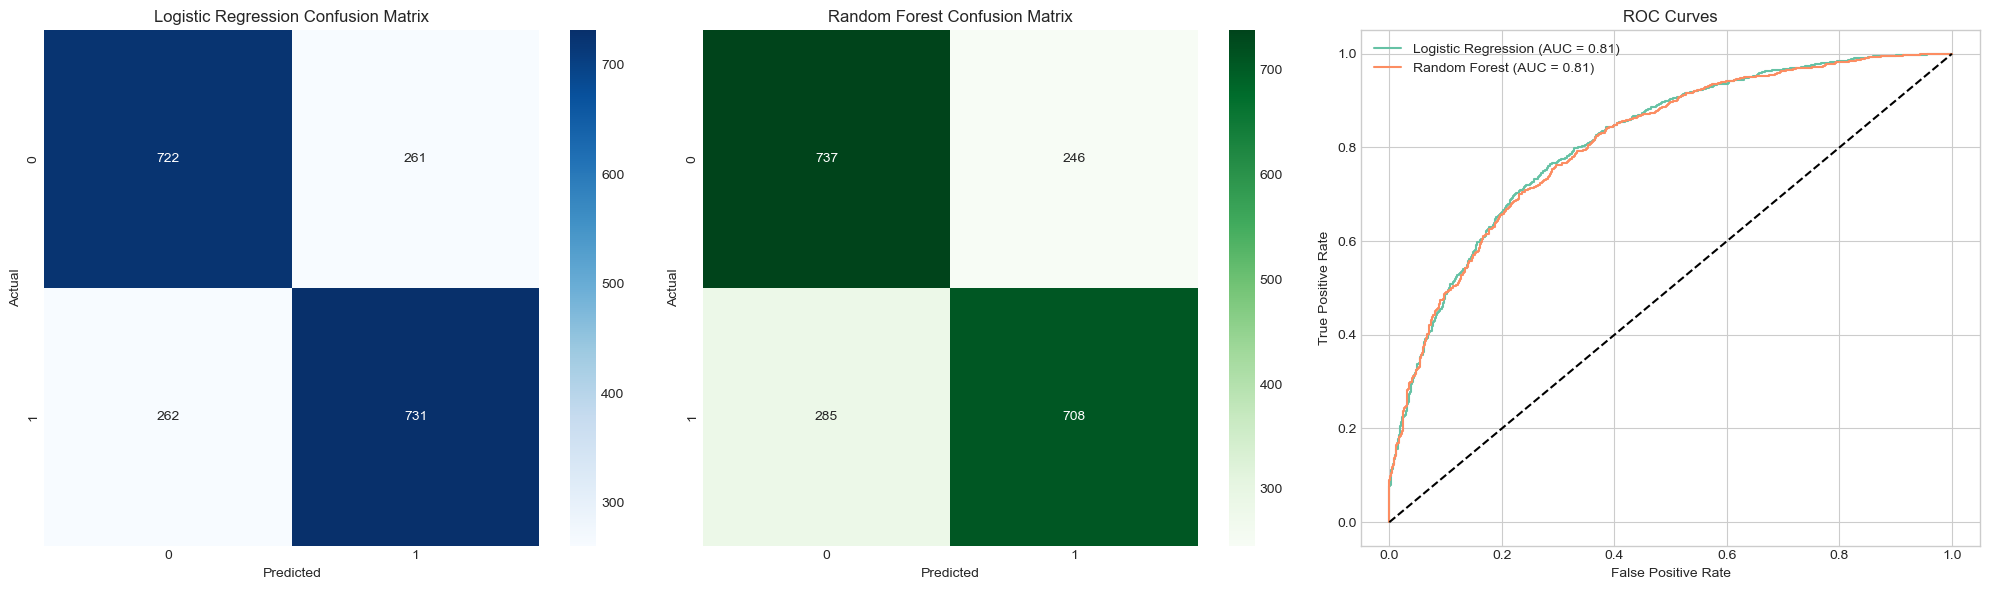

In [11]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score,roc_curve

logreg_pred = logreg.predict(X_test)
logreg_proba = logreg.predict_proba(X_test)[:, 1]

rf_pred = rf.predict(X_test)
rf_proba = rf.predict_proba(X_test)[:, 1]

#classification reports
print("Logistic Regression Classification Report:")
print(classification_report(y_test, logreg_pred))

print("Random Forest Classification Report:")
print(classification_report(y_test, rf_pred))

#visualize confusion matrices and roc curves
fig, axes = plt.subplots(1, 3, figsize=(20,6))
# Confusion Matrix for Logistic Regression
sns.heatmap(confusion_matrix(y_test, logreg_pred), annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('Logistic Regression Confusion Matrix')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

# Confusion Matrix for Random Forest
sns.heatmap(confusion_matrix(y_test, rf_pred), annot=True, fmt='d', cmap='Greens', ax=axes[1])
axes[1].set_title('Random Forest Confusion Matrix')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

# ROC Curves
logreg_fpr, logreg_tpr, _ = roc_curve(y_test, logreg_proba)
rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_proba)
axes[2].plot(logreg_fpr, logreg_tpr, label=f'Logistic Regression (AUC = {roc_auc_score(y_test, logreg_proba):.2f})')
axes[2].plot(rf_fpr, rf_tpr, label=f'Random Forest (AUC = {roc_auc_score(y_test, rf_proba):.2f})')
axes[2].plot([0, 1], [0, 1], 'k--')  
axes[2].set_title('ROC Curves')
axes[2].set_xlabel('False Positive Rate')
axes[2].set_ylabel('True Positive Rate')
axes[2].legend()
plt.tight_layout()
plt.show()



Some insights: 1. Utilizing only the first 10 minutes of game data, we achieved a high prediction accuracy of 73%, and the model showed no signs of being overly optimistic or pessimistic. 2.The ROC curve is noticeably convex toward the top left, reflecting a high hit rate and a low false positive rate. 3.The Logistic Regression and Random Forest models performed similarly, which can save computational costs.

# Causal Inference: Propensity Score Matching (PSM)

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import NearestNeighbors

# 1. Define the Treatment and Confounders
# Treatment (T): Did the Blue team secure an Objective Advantage? (1 = Yes, 0 = No)
# Confounders (X): The snowball effects (Gold, KDA, Minions) that cause BOTH the treatment and the win.

df['Treatment_ObjAdv'] = (df['blueObj_Diff'] > 0).astype(int)
confounders = ['blueGoldDiff', 'blueKDA_Diff', 'blueMinions_Diff', 'blueJungle_Diff']

# 2. Calculate the Naive Effect (Before Matching)
treated_naive = df[df['Treatment_ObjAdv'] == 1]
control_naive = df[df['Treatment_ObjAdv'] == 0]

win_rate_treated = treated_naive['blueWins'].mean()
win_rate_control = control_naive['blueWins'].mean()
naive_effect = win_rate_treated - win_rate_control

print("--- A: The Naive Observation ---")
print(f"Win Rate (With Obj Advantage): {win_rate_treated*100:.2f}%")
print(f"Win Rate (Without Obj Advantage): {win_rate_control*100:.2f}%")
print(f"Naive Effect on Win Rate: +{naive_effect*100:.2f}%\n")


# 3. Model the Propensity Score P(T=1 | X)
# Using Logistic Regression to predict the probability of getting the objective advantage.
ps_model = LogisticRegression(random_state=42)
ps_model.fit(df[confounders], df['Treatment_ObjAdv'])

# Assign the propensity score to every game in our dataset
df['Propensity_Score'] = ps_model.predict_proba(df[confounders])[:, 1]


# 4. Nearest Neighbor Matching 
treated = df[df['Treatment_ObjAdv'] == 1].reset_index(drop=True)
control = df[df['Treatment_ObjAdv'] == 0].reset_index(drop=True)

# We train the NearestNeighbors algorithm on the Control group's propensity scores
nn = NearestNeighbors(n_neighbors=1, algorithm='ball_tree')
nn.fit(control[['Propensity_Score']])

# For every Treated game, find the 1 closest Control game based on Propensity Score
distances, indices = nn.kneighbors(treated[['Propensity_Score']])

# Extract the matched control group
matched_control = control.iloc[indices.flatten()].reset_index(drop=True)

# 5. Calculate the Average Treatment Effect on the Treated (ATT)
win_rate_treated_matched = treated['blueWins'].mean()
win_rate_control_matched = matched_control['blueWins'].mean()
true_causal_effect = win_rate_treated_matched - win_rate_control_matched

print("--- B: The Causal Inference (ATT) ---")
print(f"Matched Win Rate (With Obj Advantage): {win_rate_treated_matched*100:.2f}%")
print(f"Matched Win Rate (Without Obj Advantage - But same snowball stats): {win_rate_control_matched*100:.2f}%")
print(f"TRUE Causal Effect on Win Rate: +{true_causal_effect*100:.2f}%\n")



--- A: The Naive Observation ---
Win Rate (With Obj Advantage): 58.26%
Win Rate (Without Obj Advantage): 35.20%
Naive Effect on Win Rate: +23.07%

--- B: The Causal Inference (ATT) ---
Matched Win Rate (With Obj Advantage): 58.26%
Matched Win Rate (Without Obj Advantage - But same snowball stats): 50.02%
TRUE Causal Effect on Win Rate: +8.24%

--- Final Business Insight ---
The naive observation overestimated the value of map objectives by 14.83%.
Much of the high win rate associated with taking dragons/heralds is actually a byproduct of already being rich (Gold) and winning fights (KDA).
However, the pure strategic action of securing objectives still provides a solid +8.24% independent boost to the win probability.


Insight: The naive observation overestimated the value of map objectives by 14.83%.
Much of the high win rate associated with taking dragons/heralds is actually a byproduct of already being rich (Gold) and winning fights (KDA).
However, the pure strategic action of securing objectives still provides a solid +8.24% independent boost to the win probability.